# INF201 – Deliverable 2: Campus Coffee Shop Sales Pipeline

**Group members:** Mathias Gundersen, Jakub Mermer  
**GitHub repository:** https://github.com/saltonese/Del_2-G6_5.git

## Introduction and approach

This notebook implements an ETL pipeline for the cash-register logs of the Campus Coffee chain:

1. **Extract** – recursively find all `.log` files, read them with the correct encoding (UTF-8 or ISO-8859-1) and pick out the valid sales lines with a regular expression.
2. **Transform** – build a DataFrame, remove price glitches with NumPy, and correct NOK prices that were registered on the EUR scale (× 10).
3. **Load / report** – hourly revenue per item, a status pivot table and refund ratios, written to `output/`.

Tasks 1–4 are small, individually tested building blocks. Task 5 connects them together into one .

### Interpretation choices

The assignment leaves a few things open. These are the choices made here:


### How to run
1. `python generate_data_for_d2.py` (creates `data/`; `BASE_DIR` was changed to `Path.cwd().parent / "Data"` and `random.seed(42)` added so all group members get identical data).
2. Output files are written to the `output/` folder.

In [253]:
import json
import re
import tempfile #used to make temporary files, usefull when testing along the way
from pathlib import Path #used to easyely path between files and directories

import matplotlib.pyplot as plt #used to plot graphs
import numpy as np 
import pandas as pd

print(Path.cwd())
DATA_DIR = Path.cwd().parent / "Data"
OUTPUT_DIR = Path.cwd().parent / "output"

EPSILON = 1e-6          # keeps the refund ratio finite when sales_count == 0
NOK_CORRECTION = 10.0   # NOK prices were registered on the EUR scale
OUTLIER_N_STD = 3.0     # |x - mean| > 3 * std  ->  hardware glitch

print(f"pandas {pd.__version__} | numpy {np.__version__}")
assert DATA_DIR.exists(), "Run `python generate_data_for_d2.py` first to create the Data/ folder."

c:\Users\mathi\StudieNMBU\PROG\Del_2-G6_5\Notebooks
pandas 2.3.3 | numpy 2.3.4


## Task 1 – File ingestion and regular expressions

### 1.1 Robust file reader
The file is read as raw **bytes** and decoded explicitly. Reading bytes (instead of `read_text`) also avoids platform-dependent newline translation.

* First try `utf-8` (strict). Valid UTF-8 text is easy to recognise: Latin-1 text containing `é` or `ø` is almost never valid UTF-8, so a wrong guess raises `UnicodeDecodeError`.
* If that fails, decode as `iso-8859-1`. This always succeeds because every byte value maps to a character – that is why it has to be the *second* attempt.

Note: pure-ASCII files decode identically in both encodings, so they are reported as `utf-8`. The test below uses `é` and `ø` to show that the fallback really works.

In [254]:
def read_log_file(path: str | Path) -> tuple[str, str]:
    """Read a text file whose encoding is either UTF-8 or ISO-8859-1.

    Returns
    -------
    (file_text_content, encoding_used)
    """
    path = Path(path)
    raw = path.read_bytes()
    try:
        return raw.decode("utf-8"), "utf-8"
    except UnicodeDecodeError:
        return raw.decode("iso-8859-1"), "iso-8859-1"

In [255]:
# Test: the same text saved with two different encodings
with tempfile.TemporaryDirectory() as tmp:
    tmp = Path(tmp)
    (tmp / "utf8.log").write_bytes("Café ølbar\n".encode("utf-8"))
    (tmp / "latin1.log").write_bytes("Café ølbar\n".encode("iso-8859-1"))

    text_utf8, enc_utf8 = read_log_file(tmp / "utf8.log")
    text_latin1, enc_latin1 = read_log_file(tmp / "latin1.log")

assert (enc_utf8, enc_latin1) == ("utf-8", "iso-8859-1")
assert text_utf8 == text_latin1 == "Café ølbar\n"
print("read_log_file OK:", enc_utf8, "/", enc_latin1)

read_log_file OK: utf-8 / iso-8859-1


### 1.2 Log parser with regular expressions
One compiled pattern with **named groups** matches a complete valid line. Details:

* `^ … $` anchor the pattern to the whole line, so a noise line such as `[DEBUG] BARCODE SCANNER REBOOTED` (which also starts with `[`) cannot match by accident.
* `item=(?P<item>.+?)\s+price=` is lazy, so the item name can in principle contain spaces ("Iced Latte").
* `status` is restricted to the three allowed values, so a corrupted status makes the whole line invalid instead of slipping through.
* Noise lines simply do not match and are skipped; the price is converted to `float`.

In [256]:
LOG_PATTERN = re.compile(
    r"""
    ^\[(?P<timestamp>\d{4}-\d{2}-\d{2}\ \d{2}:\d{2}:\d{2})\]\s+   # [2026-10-15 08:30:00]
    \[(?P<register_id>[A-Za-z0-9_]+)\]\s+                       # [POS_01]
    item=(?P<item>.+?)\s+                                       # item=Latte
    price=(?P<price>\d+(?:\.\d+)?)\s+                           # price=4.50
    (?P<currency>[A-Z]{3})\s+                                   # EUR / NOK / USD
    \((?P<status>SUCCESS|REFUND|CANCELLED)\)$                   # (SUCCESS)
    """,
    re.VERBOSE,
)

# Only used for the validation at the end (the parser itself ignores everything that does not match)
NOISE_PATTERN = re.compile(r"^(---.*---|===.*===|\[DEBUG\].*)$")


def parse_log_text(text: str) -> list[dict]:
    """Extract all valid sales lines from log text, ignoring system noise.

    Each record has the keys: timestamp (str), register_id (str), item (str),
    price (float), currency (str), status (str).
    """
    records = []
    for line in text.splitlines():
        match = LOG_PATTERN.match(line.strip())
        if match is None:
            continue  # noise or malformed line
        record = match.groupdict()
        record["price"] = float(record["price"])
        records.append(record)
    return records

In [257]:
sample = """--- PRINTER PAPER LOW ---
[2026-10-15 08:30:00] [POS_01] item=Latte price=4.50 EUR (SUCCESS)
[DEBUG] BARCODE SCANNER REBOOTED
=== NETWORK SYNC OK ===
[2026-10-15 08:31:12] [POS_02] item=Muffin price=999.00 NOK (REFUND)
[2026-10-15 08:32:00] [POS_02] item=Muffin price=abc NOK (REFUND)
[2026-10-15 08:33:00] [POS_02] item=Muffin price=3.50 NOK (UNKNOWN)
"""

parsed = parse_log_text(sample)
assert len(parsed) == 2
assert parsed[0] == {
    "timestamp": "2026-10-15 08:30:00",
    "register_id": "POS_01",
    "item": "Latte",
    "price": 4.5,
    "currency": "EUR",
    "status": "SUCCESS",
}
assert parsed[1]["price"] == 999.0 and parsed[1]["status"] == "REFUND"
print("parse_log_text OK ->", len(parsed), "of 7 lines are valid")

parse_log_text OK -> 2 of 7 lines are valid


## Task 2 – Recursive utility functions

### 2.1 Recursive search for log files
Explicit recursion: for every entry in a directory, a sub-directory triggers a recursive call and a file with the right extension is collected. No `glob`, `rglob` or `os.walk`. The base case is implicit – a directory without sub-directories simply makes no further recursive calls.

`iterdir()` returns entries in arbitrary order, so the workflow sorts the result to make the pipeline deterministic.

In [258]:
def find_log_files(directory: str | Path, extension: str = ".log") -> list[Path]:
    """Recursively collect all files with the given extension below `directory`."""
    directory = Path(directory)
    found: list[Path] = []
    for item in directory.iterdir():
        if item.is_dir():
            found.extend(find_log_files(item, extension))   # recursive case
        elif item.is_file() and item.suffix == extension:
            found.append(item)
    return found

In [259]:
with tempfile.TemporaryDirectory() as tmp:
    tmp = Path(tmp)
    for rel in ["2026/a/POS_01/x.log", "2026/a/POS_02/y.log", "2026/b/POS_01/z.log",
                "2026/b/POS_01/notes.txt", "top.log"]:
        file = tmp / rel
        file.parent.mkdir(parents=True, exist_ok=True)
        file.write_text("test")
    found = find_log_files(tmp)

assert sorted(p.name for p in found) == ["top.log", "x.log", "y.log", "z.log"]
assert all(isinstance(p, Path) for p in found)
print("find_log_files OK ->", sorted(p.name for p in found))

find_log_files OK -> ['top.log', 'x.log', 'y.log', 'z.log']


### 2.2 Recursive traversal of the nested config
The JSON can be any mix of dicts and lists, so the function branches on the *type* of the current node:

* **dict** – if it has `"active": true` and a string `"id"`, record the id; then recurse into every value.
* **list** – recurse into every element.
* **anything else** (str, int, bool, None) – base case, nothing to collect.

The check `is True` makes sure only a real boolean `true` counts (not e.g. the string `"yes"`).

In [260]:
def get_active_registers(node) -> set[str]:
    """Return the ids of all registers with "active": true anywhere in a nested dict/list structure."""
    active: set[str] = set()
    if isinstance(node, dict):
        if node.get("active") is True and isinstance(node.get("id"), str):
            active.add(node["id"])
        for value in node.values():
            active |= get_active_registers(value)
    elif isinstance(node, list):
        for element in node:
            active |= get_active_registers(element)
    return active    # scalars: base case -> empty set

In [261]:
example_config = {
    "company": "Campus Coffee",
    "regions": [{
        "region_name": "Main Campus",
        "stores": [{
            "name": "Library Cafe",
            "registers": [
                {"id": "POS_01", "active": True},
                {"id": "POS_02", "active": False}],
        }],
    }],
}
assert get_active_registers(example_config) == {"POS_01"}

with open(DATA_DIR / "store_config.json", encoding="utf-8") as f:
    store_config = json.load(f)
print("get_active_registers OK -> active in store_config.json:", sorted(get_active_registers(store_config)))

get_active_registers OK -> active in store_config.json: ['POS_01', 'POS_02', 'POS_03']


## Task 3 – Cleaning and analysis with NumPy

### 3.1 Removing price outliers
1. Convert to a 1-D float array (`np.asarray(..., dtype=float).ravel()`).
2. Boolean mask `|x − μ| > 3σ` (population standard deviation).
3. Replace the flagged values by the **median of the valid prices** – the median is robust and not affected by the glitches that are being removed.

Everything is vectorised; there are no Python loops over the prices. The input array is not modified (we work on a copy).

In [262]:
def remove_price_outliers(prices, n_std: float = OUTLIER_N_STD) -> np.ndarray:
    """Replace values with |x - mean| > n_std * std by the median of the remaining (valid) values."""
    values = np.asarray(prices, dtype=float).ravel()
    if values.size == 0:
        return values.copy()

    mean, std = values.mean(), values.std()          # ddof=0 (population std)
    is_outlier = np.abs(values - mean) > n_std * std

    cleaned = values.copy()
    if is_outlier.any():
        cleaned[is_outlier] = np.median(values[~is_outlier])
    return cleaned

In [263]:
rng = np.random.default_rng(0)
prices = np.append(rng.normal(5, 1, 200), [999.0, 999.0, 999.0])

cleaned = remove_price_outliers(prices)
assert cleaned.shape == prices.shape and cleaned.ndim == 1
assert not (cleaned == 999.0).any()
assert np.allclose(cleaned[-3:], np.median(prices[prices < 999]))
assert np.array_equal(cleaned[:-3], prices[:-3])      # valid values untouched
assert prices[-1] == 999.0                           # input not modified
assert remove_price_outliers(list(prices)).shape == prices.shape   # also accepts lists
print("remove_price_outliers OK")

# Known limitation of the 3-sigma rule: with n <= 10 values it can never flag anything,
# because the largest possible z-score is (n-1)/sqrt(n) < 3.
print("n=4 :", remove_price_outliers([3.0, 4.0, 5.0, 999.0]))

remove_price_outliers OK
n=4 : [  3.   4.   5. 999.]


### 3.2 Refund ratio
Element-wise `refund_count / (sales_count + ε)` with `ε = 10⁻⁶`. Only NumPy array operations are used; the ε in the denominator prevents division by zero when an item has no sales.

In [264]:
def compute_refund_ratio(sales_count: np.ndarray, refund_count: np.ndarray) -> np.ndarray:
    """Element-wise refund ratio: refund_count / (sales_count + EPSILON)."""
    sales = np.asarray(sales_count, dtype=float)
    refunds = np.asarray(refund_count, dtype=float)
    return refunds / (sales + EPSILON)

In [265]:
ratio = compute_refund_ratio(np.array([10, 0, 5, 4]), np.array([1, 0, 5, 0]))
assert np.allclose(ratio, [0.1, 0.0, 1.0, 0.0])
assert np.isfinite(ratio).all()                      # no division-by-zero problems
print("compute_refund_ratio OK ->", ratio.round(4))

compute_refund_ratio OK -> [0.1 0.  1.  0. ]


## Task 4 – Data analysis with Pandas

| Function | What it does |
|---|---|
| `build_dataframe` | records → DataFrame, `timestamp` → `datetime64` index, sorted chronologically |
| `resample_hourly_revenue` | `groupby("item")` + `resample("1h")` + `sum()` of price → Series with a `(item, hour)` MultiIndex |
| `create_status_pivot` | pivot table: rows = item, columns = status (`SUCCESS`, `REFUND`, `CANCELLED`), values = summed price |
| `item_refund_ratios` | counts `SUCCESS`/`REFUND` per item and calls `compute_refund_ratio` from Task 3 |

Passing `columns=` to the DataFrame constructor makes the functions work even for an empty record list.

In [266]:
TRANSACTION_COLUMNS = ["timestamp", "register_id", "item", "price", "currency", "status"]
STATUS_ORDER = ["SUCCESS", "REFUND", "CANCELLED"]


def build_dataframe(records: list[dict]) -> pd.DataFrame:
    """List of transaction dicts -> DataFrame indexed by (sorted) datetime timestamp."""
    
    df = pd.DataFrame(records, columns=TRANSACTION_COLUMNS)
    df["timestamp"] = pd.to_datetime(df["timestamp"])
    
    return df.set_index("timestamp").sort_index()


def resample_hourly_revenue(df: pd.DataFrame) -> pd.Series:
    """Total price per item in 1-hour windows."""
    
    return df.groupby("item")["price"].resample("1h").sum().rename("revenue")


def create_status_pivot(df: pd.DataFrame) -> pd.DataFrame:
    """Total revenue per item (rows) across the status categories (columns)."""
    
    pivot = df.pivot_table(values="price", index="item", columns="status",
                           aggfunc="sum", fill_value=0.0)
    
    return pivot.reindex(columns=STATUS_ORDER, fill_value=0.0)    # always all three columns


def item_refund_ratios(df: pd.DataFrame) -> pd.DataFrame:
    """Refund ratio per item = refunds / (successful sales + epsilon)."""
    
    counts = df.groupby(["item", "status"]).size().unstack(fill_value=0)
    counts = counts.reindex(columns=["SUCCESS", "REFUND"], fill_value=0)

    ratio = compute_refund_ratio(counts["SUCCESS"].to_numpy(), counts["REFUND"].to_numpy())
    
    return pd.DataFrame(
        {"sales_count": counts["SUCCESS"], "refund_count": counts["REFUND"], "refund_ratio": ratio},
        index=counts.index,
    )

In [267]:
demo_records = [
    {"timestamp": "2026-10-15 08:30:00", "register_id": "POS_01", "item": "Latte",  "price": 4.5, "currency": "EUR", "status": "SUCCESS"},
    {"timestamp": "2026-10-15 07:10:00", "register_id": "POS_01", "item": "Latte",  "price": 4.0, "currency": "EUR", "status": "SUCCESS"},
    {"timestamp": "2026-10-15 09:05:00", "register_id": "POS_02", "item": "Latte",  "price": 4.5, "currency": "NOK", "status": "REFUND"},
    {"timestamp": "2026-10-15 07:40:00", "register_id": "POS_02", "item": "Muffin", "price": 3.5, "currency": "USD", "status": "SUCCESS"},
]
demo_df = build_dataframe(demo_records)

assert isinstance(demo_df.index, pd.DatetimeIndex) and demo_df.index.is_monotonic_increasing

demo_hourly = resample_hourly_revenue(demo_df)

assert demo_hourly[("Latte", pd.Timestamp("2026-10-15 08:00"))] == 4.5
assert demo_hourly[("Muffin", pd.Timestamp("2026-10-15 07:00"))] == 3.5

demo_pivot = create_status_pivot(demo_df)

assert list(demo_pivot.columns) == STATUS_ORDER
assert demo_pivot.loc["Latte", "SUCCESS"] == 8.5 and demo_pivot.loc["Latte", "REFUND"] == 4.5
assert demo_pivot.loc["Muffin", "REFUND"] == 0.0

demo_ratios = item_refund_ratios(demo_df)

assert np.isclose(
    demo_ratios.loc[["Latte"], "refund_ratio"].to_numpy(dtype=np.float64),
    0.5,
).all()     # 1 / (2 + eps)

assert demo_ratios.loc["Muffin", "refund_ratio"] == 0.0
print("Task 4 functions OK")
demo_pivot

Task 4 functions OK


status,SUCCESS,REFUND,CANCELLED
item,,,
Latte,8.5,4.5,0.0
Muffin,3.5,0.0,0.0


## Task 5 – Full workflow

`run_pipeline()` performs the seven steps of the assignment in order:

1. Find log files recursively + extract active register IDs
2. Read every file (encoding detected per file) and parse the records
3. Build the DataFrame
4. NumPy outlier cleaning
5. NOK correction (× 10)
6. Hourly resample, pivot table, refund ratios
7. Save the four output files to `output/`

**Order matters:** outliers are removed *before* the NOK correction, so glitches are detected on the raw price scale and the correction is applied to clean values only.

In [268]:
def hourly_to_nested_dict(hourly: pd.Series) -> dict[str, dict[str, float]]:
    """(item, hour) Series -> {item: {"YYYY-MM-DD HH:MM:SS": revenue}} (JSON needs string keys)."""
    result: dict[str, dict[str, float]] = {}
    for (item, hour), revenue in hourly.items():
        result.setdefault(item, {})[hour.strftime("%Y-%m-%d %H:%M:%S")] = round(float(revenue), 2)
    return result


def run_pipeline(data_dir: Path = DATA_DIR, output_dir: Path = OUTPUT_DIR) -> dict:
    output_dir.mkdir(parents=True, exist_ok=True)

    # 1. Discover log files and active registers
    log_files = sorted(find_log_files(data_dir))
    with open(data_dir / "store_config.json", encoding="utf-8") as f:
        active_registers = get_active_registers(json.load(f))
    print(f"[1/7] {len(log_files)} log files found, active registers: {sorted(active_registers)}")

    # 2. Ingest + parse
    records: list[dict] = []
    encodings: dict[str, str] = {}
    for path in log_files:
        text, encoding = read_log_file(path)
        encodings[path.relative_to(data_dir).as_posix()] = encoding
        records.extend(parse_log_text(text))
    n_parsed = len(records)
    records = [r for r in records if r["register_id"] in active_registers]
    print(f"[2/7] {n_parsed} records parsed, {n_parsed - len(records)} dropped (inactive register)")

    # 3. DataFrame
    raw_df = build_dataframe(records)
    print(f"[3/7] DataFrame built: {raw_df.shape[0]} rows, index {raw_df.index.min()} -> {raw_df.index.max()}")

    # 4. Outlier cleaning (NumPy)
    df = raw_df.copy()
    cleaned_prices = remove_price_outliers(df["price"].to_numpy())
    n_outliers = int((cleaned_prices != df["price"].to_numpy()).sum())
    df["price"] = cleaned_prices
    print(f"[4/7] {n_outliers} outlier prices replaced by the median of the valid prices")

    # 5. NOK correction
    is_nok = df["currency"] == "NOK"
    df.loc[is_nok, "price"] = df.loc[is_nok, "price"] * NOK_CORRECTION
    df["price"] = df["price"].round(2)
    print(f"[5/7] {int(is_nok.sum())} NOK prices multiplied by {NOK_CORRECTION}")

    # 6. Reports
    hourly = resample_hourly_revenue(df)
    pivot = create_status_pivot(df)
    ratios = item_refund_ratios(df)
    print(f"[6/7] hourly revenue ({len(hourly)} item-hour rows), pivot {pivot.shape}, refund ratios {ratios.shape}")

    # 7. Save
    df.to_csv(output_dir / "cleaned_transactions.csv", index_label="timestamp")
    with open(output_dir / "hourly_revenue.json", "w", encoding="utf-8") as f:
        json.dump(hourly_to_nested_dict(hourly), f, indent=2)
    pivot.to_csv(output_dir / "status_pivot_table.csv")
    ratios.to_csv(output_dir / "item_refund_ratios.csv")
    print(f"[7/7] 4 output files written to {output_dir.resolve()}")

    return {
        "log_files": log_files, "active_registers": active_registers, "encodings": encodings,
        "raw_df": raw_df, "clean_df": df, "n_outliers": n_outliers,
        "hourly": hourly, "pivot": pivot, "ratios": ratios,
    }

In [269]:
results = run_pipeline()

[1/7] 9 log files found, active registers: ['POS_01', 'POS_02', 'POS_03']
[2/7] 720 records parsed, 0 dropped (inactive register)
[3/7] DataFrame built: 720 rows, index 2026-10-15 07:01:33 -> 2026-10-15 09:26:13
[4/7] 25 outlier prices replaced by the median of the valid prices
[5/7] 218 NOK prices multiplied by 10.0
[6/7] hourly revenue (18 item-hour rows), pivot (6, 3), refund ratios (6, 3)
[7/7] 4 output files written to C:\Users\mathi\StudieNMBU\PROG\Del_2-G6_5\output


## 6. Results

### 6.1 Encoding detected per file
The generator writes every second file as Latin-1, but the content is pure ASCII, which is byte-identical in both encodings – so all files are legitimately reported as UTF-8. Section 2 (Task 1) showed that the Latin-1 fallback works for real non-ASCII text.

In [270]:
pd.Series(results["encodings"], name="encoding_used").to_frame()

,encoding_used
2026/library_cafe/POS_01/register_sales.log,utf-8
2026/library_cafe/POS_02/register_sales.log,utf-8
2026/library_cafe/POS_03/register_sales.log,utf-8
2026/science_building/POS_01/register_sales.log,utf-8
2026/science_building/POS_02/register_sales.log,utf-8
2026/science_building/POS_03/register_sales.log,utf-8
2026/student_union/POS_01/register_sales.log,utf-8
2026/student_union/POS_02/register_sales.log,utf-8
2026/student_union/POS_03/register_sales.log,utf-8


### 6.2 Cleaned transactions

In [271]:
results["clean_df"].head(10)

,register_id,item,price,currency,status
timestamp,,,,,
2026-10-15 07:01:33,POS_03,Latte,4.54,EUR,SUCCESS
2026-10-15 07:01:49,POS_02,Croissant,4.00,USD,REFUND
2026-10-15 07:01:53,POS_02,Sandwich,7.66,EUR,SUCCESS
2026-10-15 07:02:04,POS_01,Espresso,3.33,EUR,REFUND
2026-10-15 07:02:07,POS_02,Sandwich,4.00,EUR,SUCCESS
2026-10-15 07:02:11,POS_03,Sandwich,7.35,EUR,SUCCESS
2026-10-15 07:02:12,POS_03,Croissant,4.17,USD,SUCCESS
2026-10-15 07:02:23,POS_01,Cappuccino,37.80,NOK,SUCCESS
2026-10-15 07:02:53,POS_01,Cappuccino,4.44,EUR,CANCELLED


### 6.3 Total revenue per item and status (Task 4.3)

In [272]:
results["pivot"].round(2)

status,SUCCESS,REFUND,CANCELLED
item,,,
Cappuccino,1640.00,294.93,262.67
Croissant,1321.48,184.98,481.97
Espresso,885.04,116.04,209.33
Latte,994.92,308.53,579.31
Muffin,1037.26,246.30,322.41
Sandwich,1872.64,413.72,481.11


### 6.4 Refund ratio per item (Task 4.4)

In [273]:
results["ratios"].round(4)

,sales_count,refund_count,refund_ratio
item,,,
Cappuccino,92,18,0.1957
Croissant,83,20,0.2410
Espresso,70,19,0.2714
Latte,76,24,0.3158
Muffin,79,16,0.2025
Sandwich,73,19,0.2603


### 6.5 Hourly revenue per item (Task 4.2) – first rows

In [274]:
results["hourly"].round(2).head(12).to_frame()

revenue
item       timestamp                   
Cappuccino 2026-10-15 07:00:00   877.14
           2026-10-15 08:00:00  1163.41
           2026-10-15 09:00:00   157.05
Croissant  2026-10-15 07:00:00   856.93
           2026-10-15 08:00:00   946.61
           2026-10-15 09:00:00   184.89
Espresso   2026-10-15 07:00:00   556.00
           2026-10-15 08:00:00   531.09
           2026-10-15 09:00:00   123.32
Latte      2026-10-15 07:00:00   892.71
           2026-10-15 08:00:00   853.01
           2026-10-15 09:00:00   137.04

### 6.6 Plots

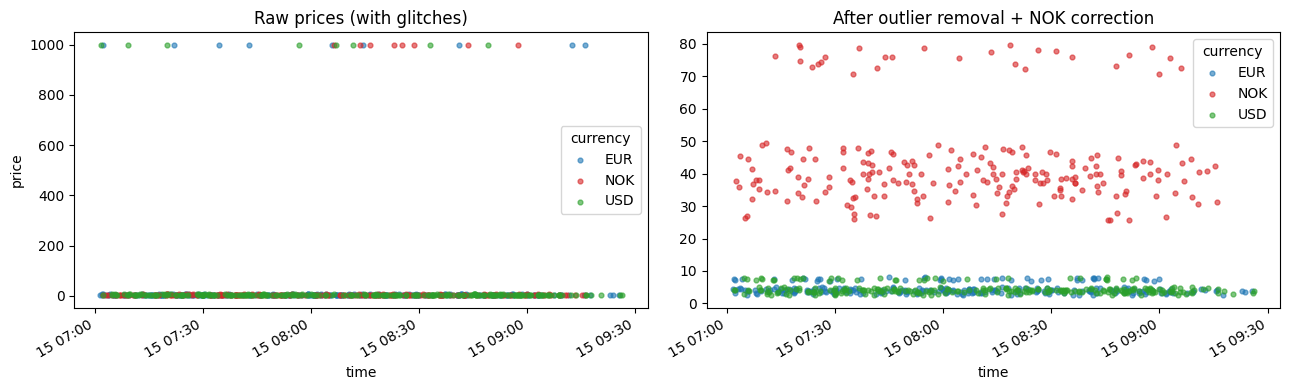

In [276]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharex=True)
colors = {"EUR": "tab:blue", "NOK": "tab:red", "USD": "tab:green"}

for ax, frame, title in [(axes[0], results["raw_df"], "Raw prices (with glitches)"),
                         (axes[1], results["clean_df"], "After outlier removal + NOK correction")]:
    for currency, group in frame.groupby("currency"):
        ax.scatter(group.index, group["price"], s=12, alpha=0.6, label=currency, color=colors[currency])
    ax.set_title(title)
    ax.set_xlabel("time")
    ax.legend(title="currency")
axes[0].set_ylabel("price")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

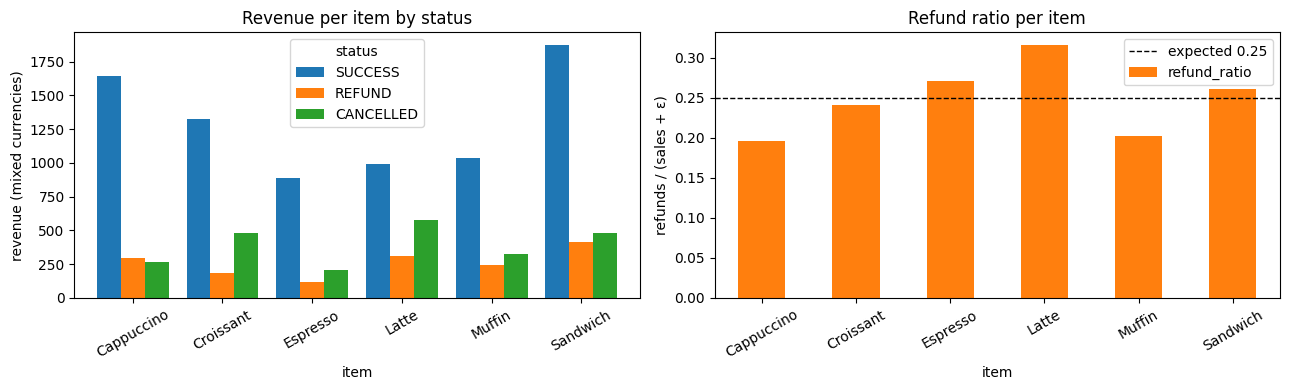

In [278]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

results["pivot"].plot(kind="bar", ax=axes[0], width=0.8)
axes[0].set_title("Revenue per item by status")
axes[0].set_ylabel("revenue (mixed currencies)")
axes[0].tick_params(axis="x", rotation=30)

results["ratios"]["refund_ratio"].plot(kind="bar", ax=axes[1], color="tab:orange")
axes[1].axhline(0.25, color="black", linestyle="--", linewidth=1, label="expected 0.25")
axes[1].set_title("Refund ratio per item")
axes[1].set_ylabel("refunds / (sales + ε)")
axes[1].tick_params(axis="x", rotation=30)
axes[1].legend()

plt.tight_layout()
plt.show()